---
title: "Titanic EDA mit Numpy, erster Anlauf"
short_title: "Titanic EDA"
description: "Der Titanic-Datensatz, analysiert allein mit Numpy: fehlende Werte, Überlebensraten nach Geschlecht, ein erster Klassifikator und ein Blick auf Korrelationen."
---

[Vorlesungsaufzeichnung Datenexploration mit Numpy](https://media.hhu.de/channel/video/data-science-vl-6-eda-numpy-2025/64e568d28c23f0098ac57359e1ca5750/167?t=1596)

In diesem Notebook nutzen wir nur Numpy (kein Pandas, Scikit-learn o.ä.) um eine diskrete Analyse des Kaggle-Titanic-Datensatzes durchzuführen. Die naheliegenden Aufgaben sind explorative Analyse (EDA) und das Modellieren der Variable 'Überlebenswahrscheinlichkeit' für die Instanzen (ein Auszug aus der Passagierliste der Titanic). Wir wollen am Rande zur Motivation auch eine erste multivariate Analyse betrachten, auch wenn wir die Theorie dazu noch nicht besprochen haben.

## Daten laden

Wir werden erstmal naiv die Komma-separierte Datei von Kaggle (die mit Überschriften daher kommt) laden, und schauen, was passiert.

In [1]:
import numpy as np

filename = 'titanic.csv'

try:
    data = np.genfromtxt(
        filename,
        delimiter=',',
        dtype=None,
        encoding='utf-8',
        names=True
    )
except ValueError as e:
    print("\n".join(e.args[0].split("\n")[:3]), "\n\t...")

Some errors were detected !
    Line #2 (got 13 columns instead of 12)
    Line #3 (got 13 columns instead of 12) 
	...


Offenbar enthält Zeile 2 mehr Variablen als die Überschriftzeile!

Wir drucken uns die ersten zwei Zeilen zur manuellen Inspektion aus:

In [2]:
with open(filename, "r") as file:
    for i in range(2):
        print(file.readline())

PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked

1,0,3,"Braund, Mr. Owen Harris",male,22,1,0,A/5 21171,7.25,,S



Die Lösung ist ein CSV-Parser, der Anführungszeichen versteht: In `"Braund, Mr. Owen Harris"` ist das Komma Teil des Namens und kein Trennzeichen. Das `csv`-Modul aus der Python-Standardbibliothek kann das (und `pandas.read_csv`, das wir später kennenlernen, ebenfalls). `np.genfromtxt` kennt keine Anführungszeichen, deshalb schreiben wir die Datei einmal als TSV (tab-separated values) neu. In den Werten kommt kein Tabulator vor, also braucht das TSV keine Anführungszeichen mehr:

In [3]:
import csv

with open("titanic.csv", newline="", encoding="utf-8") as quelle, \
     open("titanic.tsv", "w", encoding="utf-8") as ziel:
    for zeile in csv.reader(quelle):        # liest "Braund, Mr. Owen Harris" als ein Feld
        assert not any("\t" in feld for feld in zeile)   # sonst bräuchten wir wieder Anführungszeichen
        ziel.write("\t".join(zeile) + "\n")

In [4]:
filename = 'titanic.tsv'

data = np.genfromtxt(
    filename,
    delimiter='\t',
    dtype=None,
    encoding='utf-8',
    names=True
)

In [5]:
print("Columns:", data.dtype.names)
print("First 5 rows:")
print(data[:5])

Columns: ('PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked')
First 5 rows:
[(1, 0, 3, 'Braund, Mr. Owen Harris', 'male', 22., 1, 0, 'A/5 21171',  7.25  , '', 'S')
 (2, 1, 1, 'Cumings, Mrs. John Bradley (Florence Briggs Thayer)', 'female', 38., 1, 0, 'PC 17599', 71.2833, 'C85', 'C')
 (3, 1, 3, 'Heikkinen, Miss. Laina', 'female', 26., 0, 0, 'STON/O2. 3101282',  7.925 , '', 'S')
 (4, 1, 1, 'Futrelle, Mrs. Jacques Heath (Lily May Peel)', 'female', 35., 1, 0, '113803', 53.1   , 'C123', 'S')
 (5, 0, 3, 'Allen, Mr. William Henry', 'male', 35., 0, 0, '373450',  8.05  , '', 'S')]


## Relevante Features auswählen

In [6]:
survived = data['Survived'].astype(int)
pclass = data['Pclass'].astype(int)
sex = data['Sex']
age = data['Age']  # may contain nan
sibsp = data['SibSp'].astype(int)
parch = data['Parch'].astype(int)
embarked = data['Embarked']

used_columns = {'Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Embarked'}
all_columns = set(data.dtype.names)
unused_columns = all_columns - used_columns
print("Unused columns:", unused_columns)

Unused columns: {'PassengerId', 'Cabin', 'Ticket', 'Name', 'Fare'}


## NaN = Not a Number

Ob man fehlende Werte durch den Median ersetzt oder die Zeilen weglässt, ist eine Entscheidung, die Daten verfälscht; wie man sie systematisch trifft und protokolliert, steht im Kapitel [Daten putzen](data-cleaning.ipynb).


In [7]:
print("\nAnzahl fehlender Alterswerte:", np.sum(np.isnan(age)))

# Fehlende Alterswerte durch den Median ersetzen (nur als Beispiel)
non_nan_age = age[~np.isnan(age)]
age_filled = age.copy()
age_filled[np.isnan(age)] = np.median(non_nan_age)

print("Fehlende Alterswerte ersetzt durch den Median:", np.median(non_nan_age))


Anzahl fehlender Alterswerte: 177
Fehlende Alterswerte ersetzt durch den Median: 28.0


## Überleben analysieren

In [8]:
# neues Feature
def survival_rate(mask):
    total = np.sum(mask)
    survived_total = np.sum(survived[mask])
    rate = survived_total / total if total > 0 else 0
    return total, survived_total, rate

# Gruppieren nach Sex
for s in np.unique(sex):
    mask = (sex == s)
    total, survived_s, rate = survival_rate(mask)
    print(f"Sex: {s:6s} | Anzahl: {total:3d} | Überlebt: {survived_s:3d} | Anteil: {rate:.2f}")

# Gruppieren nach Passenger Class
for c in np.unique(pclass):
    mask = (pclass == c)
    total, survived_c, rate = survival_rate(mask)
    print(f"Pclass: {c} | Anzahl: {total:3d} | Überlebt: {survived_c:3d} | Anteil: {rate:.2f}")

# Binning
missing = np.isnan(age)  # fehlende Einträge getrennt merken, kein Sentinel-Wert!

age_group = np.full(age.shape, 'Unknown', dtype='<U10')
age_group[~missing] = 'Adult'
age_group[~missing & (age < 13)] = 'Child'
age_group[~missing & (age >= 60)] = 'Senior'

for grp in np.unique(age_group):
    mask = (age_group == grp)
    total, survived_grp, rate = survival_rate(mask)
    print(f"Age Group: {grp:7s} | Total: {total:3d} | Survived: {survived_grp:3d} | Rate: {rate:.2f}")

Sex: female | Anzahl: 314 | Überlebt: 233 | Anteil: 0.74
Sex: male   | Anzahl: 577 | Überlebt: 109 | Anteil: 0.19
Pclass: 1 | Anzahl: 216 | Überlebt: 136 | Anteil: 0.63
Pclass: 2 | Anzahl: 184 | Überlebt:  87 | Anteil: 0.47
Pclass: 3 | Anzahl: 491 | Überlebt: 119 | Anteil: 0.24
Age Group: Adult   | Total: 619 | Survived: 243 | Rate: 0.39
Age Group: Child   | Total:  69 | Survived:  40 | Rate: 0.58
Age Group: Senior  | Total:  26 | Survived:   7 | Rate: 0.27
Age Group: Unknown | Total: 177 | Survived:  52 | Rate: 0.29


## Visualisierung: Überleben nach Geschlecht

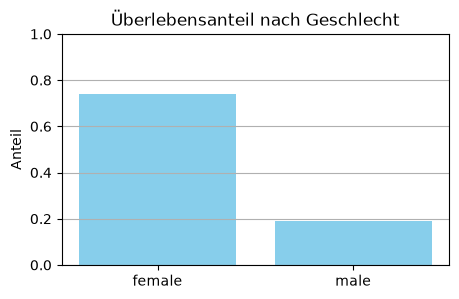

In [9]:
import matplotlib.pyplot as plt

labels = []
rates = []
for s in np.unique(sex):
    mask = (sex == s)
    _, _, rate = survival_rate(mask)
    labels.append(s)
    rates.append(rate)

plt.figure(figsize=(5, 3))
plt.bar(labels, rates, color='skyblue')
plt.title('Überlebensanteil nach Geschlecht')
plt.ylabel('Anteil')
plt.ylim(0, 1)
plt.grid(axis='y')
plt.show()

## Ein erster Klassifikator

Die Überlebensquoten oben legen eine Regel nahe: „Frauen überleben, Männer nicht.“ Eine Regel, die aus den Merkmalen einer Zeile ein **Label** macht (hier die Spalte `Survived`), heißt **Klassifikator**. Das Label ist die Spalte, die wir vorhersagen wollen und die für die vorhandenen Zeilen bekannt ist, die *Ground Truth*. Bevor wir irgendein Verfahren lernen, das so eine Regel selbst aus Daten findet, schauen wir, wie man eine Regel bewertet. Dazu brauchen wir nichts als Masken:

In [10]:
prediction = (sex == 'female')    # Vorhersage: überlebt
truth = (survived == 1)           # Ground Truth

tp = np.sum( prediction &  truth)   # richtig positiv: überlebt vorhergesagt, hat überlebt
fp = np.sum( prediction & ~truth)   # falsch positiv:  überlebt vorhergesagt, ist gestorben
fn = np.sum(~prediction &  truth)   # falsch negativ:  gestorben vorhergesagt, hat überlebt
tn = np.sum(~prediction & ~truth)   # richtig negativ: gestorben vorhergesagt, ist gestorben

print("                        vorhergesagt: gestorben  überlebt")
print(f"tatsächlich gestorben:                  {tn:4d}      {fp:4d}")
print(f"tatsächlich überlebt:                   {fn:4d}      {tp:4d}")
assert tp + fp + fn + tn == len(survived)

                        vorhergesagt: gestorben  überlebt
tatsächlich gestorben:                   468        81
tatsächlich überlebt:                    109       233


Diese $2 \times 2$-Tabelle heißt **Konfusionsmatrix**. Sie ist nichts anderes als eine Kreuztabelle zweier nominaler Variablen, Ground Truth gegen Vorhersage, und damit genau die Art Maßzahl, die das Kapitel [Deskriptive Statistik](deskriptive-statistik.md) für nominale Merkmale erlaubt. Aus ihr liest man drei gebräuchliche Kennzahlen ab:

* **Accuracy** (Treffergenauigkeit): der Anteil der richtigen Vorhersagen, $\dfrac{tp + tn}{n}$.
* **Precision** (Genauigkeit): Wenn wir „überlebt“ vorhersagen, wie oft stimmt das? $\dfrac{tp}{tp + fp}$.
* **Recall** (Trefferquote, in der Medizin *Sensitivität*): Von den tatsächlich Überlebenden, wie viele erwischen wir? $\dfrac{tp}{tp + fn}$.

Precision und Recall sind bedingte Wahrscheinlichkeiten, nur in verschiedene Richtungen gelesen: Precision ist $P(\text{überlebt} \mid \text{vorhergesagt})$, Recall ist $P(\text{vorhergesagt} \mid \text{überlebt})$. Dass das zwei verschiedene Zahlen sind, wird uns beim [Satz von Bayes](kovarianz.md) wieder begegnen.

In [11]:
n = len(survived)

def kennzahlen(prediction):
    tp = np.sum( prediction &  truth); fp = np.sum( prediction & ~truth)
    fn = np.sum(~prediction &  truth); tn = np.sum(~prediction & ~truth)
    accuracy  = (tp + tn) / n
    precision = tp / (tp + fp) if tp + fp > 0 else np.nan   # ohne positive Vorhersage undefiniert
    recall    = tp / (tp + fn)
    return accuracy, precision, recall

for name, pred in [("Frauen überleben", sex == 'female'),
                   ("niemand überlebt", np.zeros(n, dtype=bool))]:
    acc, prec, rec = kennzahlen(pred)
    print(f"{name:18s} Accuracy {acc:.3f}   Precision {prec:.3f}   Recall {rec:.3f}")

Frauen überleben   Accuracy 0.787   Precision 0.742   Recall 0.681
niemand überlebt   Accuracy 0.616   Precision nan   Recall 0.000


Die zweite Zeile ist der dümmste Klassifikator, den es gibt: Er sagt für alle Zeilen die häufigste Klasse vorher. Trotzdem liegt er in 62 % der Fälle richtig, weil nur 38 % der Passagiere überlebt haben. Daran sieht man, dass Accuracy allein wenig sagt; sie muss immer gegen die **Basisrate** der häufigsten Klasse gehalten werden. Recall und Precision entlarven die Regel sofort: Recall $0$, Precision undefiniert.

Der dümmste Klassifikator ist übrigens ein alter Bekannter. Im Kapitel [Erwartungswert und Varianz](erwartungswert.md) waren Median und Mittelwert die besten *konstanten* Modelle für den absoluten und den quadratischen Fehler. Für ein nominales Label ist das beste konstante Modell der **Modus**, die häufigste Klasse, und der Fehler, den er minimiert, ist die Fehlklassifikationsrate $1 - \text{Accuracy}$.

Man kann die Regel verfeinern, etwa nach der Losung „Frauen und Kinder zuerst“:

In [12]:
acc, prec, rec = kennzahlen((sex == 'female') | (~missing & (age < 13)))
print(f"Frauen und Kinder  Accuracy {acc:.3f}   Precision {prec:.3f}   Recall {rec:.3f}")

Frauen und Kinder  Accuracy 0.792   Precision 0.724   Recall 0.743


Die Accuracy ändert sich kaum, aber Recall steigt und Precision fällt: Die neue Regel erwischt mehr Überlebende, hält dafür aber auch mehr Verstorbene für Überlebende. Welche der beiden Kennzahlen zählt, hängt von der Frage ab. Wer Rettungsboote plant, will keinen Überlebenden übersehen (Recall); wer Spam aussortiert, will keine echte Mail wegwerfen (Precision). Weil man oft eine einzige Zahl braucht, fasst man beide im **F1-Score** zusammen, dem harmonischen Mittel aus Precision und Recall. Das Kapitel [Modell-Auswahl](model-selection.ipynb) lässt scikit-learn diese Tabelle für uns rechnen.

Eine Sache haben wir uns hier erlaubt, die man später nie wieder tun darf: Wir haben die Regel auf denselben Daten bewertet, an denen wir sie uns ausgedacht haben. Wie man Daten zurückhält, um eine Regel ehrlich zu bewerten, steht ebenfalls im Kapitel Modell-Auswahl unter *Train-Test-Split*.

### Zwei Richtungen

Die Konfusionsmatrix enthält noch eine Lektion, die wir hier nur ansehen und erst im Kapitel [Kovarianz und Abhängigkeit](kovarianz.md) beweisen. Die Precision der Regel „Frauen überleben“ ist der Anteil der Überlebenden unter den Frauen, der Recall ist der Anteil der Frauen unter den Überlebenden:

In [13]:
p_ueberlebt_wenn_frau = np.mean(survived[sex == 'female'])         # P(überlebt | weiblich) = Precision
p_frau_wenn_ueberlebt = np.mean(sex[survived == 1] == 'female')    # P(weiblich | überlebt) = Recall
p_frau = np.mean(sex == 'female')      # Basisrate: Frauenanteil
p_ueberlebt = np.mean(survived)        # Basisrate: Überlebensrate

print(f"P(überlebt | weiblich) = {p_ueberlebt_wenn_frau:.3f}")
print(f"P(weiblich | überlebt) = {p_frau_wenn_ueberlebt:.3f}")
print(f"Umrechnung: {p_frau_wenn_ueberlebt:.3f} * {p_ueberlebt:.3f} / {p_frau:.3f}"
      f" = {p_frau_wenn_ueberlebt * p_ueberlebt / p_frau:.3f}")

P(überlebt | weiblich) = 0.742
P(weiblich | überlebt) = 0.681
Umrechnung: 0.681 * 0.384 / 0.352 = 0.742


Die beiden bedingten Wahrscheinlichkeiten sind verschieden, und der Umrechnungsfaktor zwischen ihnen ist das Verhältnis der beiden Basisraten. Das ist, mit selbst gezählten Zahlen, der **Satz von Bayes**.

## Blick auf Korrelationen

Wir haben noch nicht formal eingeführt, was das ist, aber so lassen wir schnell den sogenannten Korrelationskoeffizienten ausrechnen. Wir können uns für später aufheben, wie wir das interpretieren, was wir hier sehen.

In [14]:
is_female = (sex == 'female').astype(int)
is_male = (sex == 'male').astype(int)

corf = np.corrcoef(survived, is_female)[0, 1]
corm = np.corrcoef(survived, is_male)[0, 1]

print(f"Correlation between being female and survival: {corf:.2f}")
print(f"Correlation between being male and survival: {corm:.2f}")

Correlation between being female and survival: 0.54
Correlation between being male and survival: -0.54
